# Spike-Train Distances and Synchrony

This tutorial covers the pairwise spike-train measures of `braintools.metric`. Each one answers a slightly different question, and several have properties that are easy to misread, so every section checks a function against a case with a known answer.

| Function | Input | Measures |
|---|---|---|
| `victor_purpura_distance(t1, t2, cost_factor)` | spike times | edit distance: shifting a spike by $\Delta t$ costs $q\lvert\Delta t\rvert$, adding or removing one costs 1 |
| `van_rossum_distance(t1, t2, tau)` | spike times | distance between exponentially filtered trains |
| `spike_train_synchrony(spikes, window_size, dt)` | spike matrix | fraction of spikes with a partner in another train within the window |
| `correlation_index(spikes, window_size, dt)` | spike matrix | mean Pearson correlation of binned counts |
| `spike_time_tiling_coefficient(spikes, dt, tau)` | spike matrix | STTC, a coincidence measure that is 0 for independent trains |
| `phase_locking_value(spikes, reference_freq, dt)` | spike matrix | locking of each neuron's spikes to an external rhythm |
| `burst_synchrony_index(spikes, burst_threshold, max_isi, dt)` | spike matrix | co-occurrence of detected bursts |

The first two take arrays of spike times; the others take a `(T, N)` spike matrix plus `dt`. Pass time arguments as `brainunit` quantities and units are converted; the distance functions take plain numbers in one consistent unit.

## 1. Setup

In [1]:
import brainunit as u
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import braintools.metric as bm

rng = np.random.default_rng(0)
dt = 1 * u.ms

## 2. Victor-Purpura Distance

The distance is the cheapest way to turn one train into the other. The cost factor $q$ (units of 1/time) sets the time scale: two spikes closer than $2/q$ are cheaper to shift than to delete and re-insert. For $q \to 0$ the distance is the difference in spike counts; for large $q$ it counts the spikes that do not match exactly.

In [2]:
a = np.array([10.0, 30.0, 50.0, 70.0, 90.0])  # ms
b = a + 2.0  # every spike shifted by 2 ms
c = np.array([10.0, 50.0, 90.0])

print("identical:", bm.victor_purpura_distance(a, a, cost_factor=1.0))
for q in [0.01, 0.1, 1.0, 10.0]:
    d = bm.victor_purpura_distance(a, b, cost_factor=q)
    print(f"q = {q:5.2f}/ms: shifted by 2 ms -> {float(d):.2f}  (min(5 * q * 2, 10) = {min(5 * q * 2, 10):.2f})")
print("q -> 0, a vs c (5 vs 3 spikes):", float(bm.victor_purpura_distance(a, c, cost_factor=1e-6)), "(count difference 2)")

identical: 0.0
q =  0.01/ms: shifted by 2 ms -> 0.10  (min(5 * q * 2, 10) = 0.10)
q =  0.10/ms: shifted by 2 ms -> 1.00  (min(5 * q * 2, 10) = 1.00)
q =  1.00/ms: shifted by 2 ms -> 10.00  (min(5 * q * 2, 10) = 10.00)
q = 10.00/ms: shifted by 2 ms -> 10.00  (min(5 * q * 2, 10) = 10.00)
q -> 0, a vs c (5 vs 3 spikes): 2.0 (count difference 2)


## 3. van Rossum Distance

Each train is filtered with the causal kernel $K(t) = \frac1\tau e^{-t/\tau}$ and the distance is $D = \sqrt{\int (f_1 - f_2)^2\,dt}$. It is evaluated in closed form. For two single spikes a time $\Delta$ apart,

$$D^2 = \frac{1}{\tau}\left(1 - e^{-\Delta/\tau}\right),$$

so small shifts cost little when $\tau \gg \Delta$, and $D^2 \to 1/\tau$ (two unrelated spikes) when $\Delta \gg \tau$.

In [3]:
print(f"{'tau':>5s} {'Delta':>6s} {'D':>8s} {'closed form':>12s}")
for tau in [1.0, 10.0]:
    for delta in [0.5, 5.0, 50.0]:
        D = float(bm.van_rossum_distance(np.array([100.0]), np.array([100.0 + delta]), tau=tau, t_max=1000.0))
        print(f"{tau:5.0f} {delta:6.1f} {D:8.4f} {np.sqrt((1 - np.exp(-delta / tau)) / tau):12.4f}")

  tau  Delta        D  closed form


    1    0.5   0.6273       0.6273
    1    5.0   0.9966       0.9966
    1   50.0   1.0000       1.0000
   10    0.5   0.0698       0.0698
   10    5.0   0.1984       0.1984
   10   50.0   0.3152       0.3152


The default integration end is the last spike plus $5\tau$, which leaves out less than $e^{-10}$ of each kernel's squared tail; pass `t_max` to integrate further. Here is the distance as a function of the shift between the two 5-spike trains:

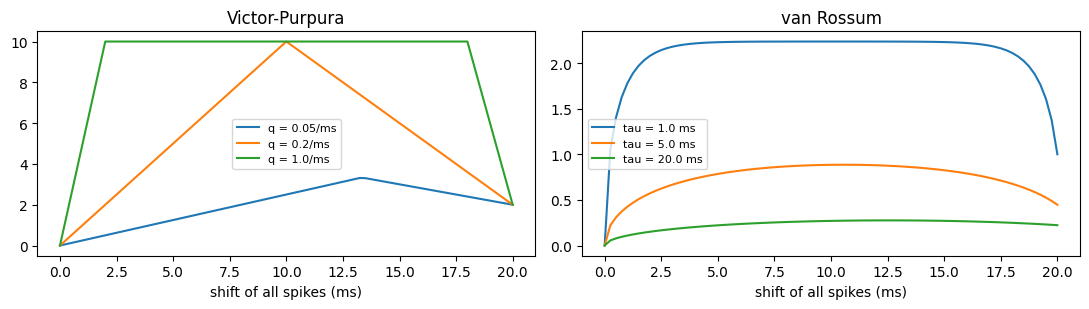

In [4]:
shifts = np.linspace(0, 20, 81)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for q in [0.05, 0.2, 1.0]:
    axes[0].plot(shifts, [float(bm.victor_purpura_distance(a, a + s, cost_factor=q)) for s in shifts], label=f"q = {q}/ms")
for tau in [1.0, 5.0, 20.0]:
    axes[1].plot(shifts, [float(bm.van_rossum_distance(a, a + s, tau=tau)) for s in shifts], label=f"tau = {tau} ms")
axes[0].set_title("Victor-Purpura")
axes[1].set_title("van Rossum")
for ax in axes:
    ax.set_xlabel("shift of all spikes (ms)")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 4. Coincidence Measures and Firing Rate

Three functions summarize synchrony from a spike matrix:

- `spike_train_synchrony`: for each pair, the fraction of spikes that have a partner in the other train within `window_size / 2`, averaged over pairs. Between 0 and 1.
- `correlation_index`: the mean Pearson correlation of spike counts in bins of `window_size`.
- `spike_time_tiling_coefficient` (STTC, Cutts & Eglen 2014): compares the fraction of A's spikes within $\pm\tau$ of a B spike with the fraction of time covered by $\pm\tau$ windows around B's spikes. Matrix output, 1 on the diagonal. The default is $\tau = 5$ ms.

The crucial difference shows up with **independent** trains at increasing rates. A coincidence fraction grows simply because there are more spikes to coincide with, whereas STTC and the correlation index subtract what chance predicts:

In [5]:
T = 20_000  # 20 s at dt = 1 ms
print(f"{'rate':>6s} {'synchrony':>10s} {'corr. index':>12s} {'STTC':>7s}   independent trains, window 10 ms")
for rate in [2, 10, 50]:
    s = (rng.random((T, 10)) < rate * 1e-3).astype(float)
    sync = float(bm.spike_train_synchrony(s, window_size=10 * u.ms, dt=dt))
    ci = float(bm.correlation_index(s, window_size=10 * u.ms, dt=dt))
    sttc = np.asarray(bm.spike_time_tiling_coefficient(s, dt=dt, tau=5 * u.ms))
    print(f"{rate:4d}Hz {sync:10.3f} {ci:12.3f} {sttc[np.triu_indices(10, 1)].mean():7.3f}")

  rate  synchrony  corr. index    STTC   independent trains, window 10 ms


   2Hz      0.023        0.001   0.001


  10Hz      0.104        0.001   0.001


  50Hz      0.435        0.005   0.004


With a real shared component the chance-corrected measures rise above zero. Ten trains share 100 events (each train joins 60 % of them, jittered by up to $\pm 2$ ms) on top of 10 Hz background:

In [6]:
s = (rng.random((T, 10)) < 0.01).astype(float)
shared_events = rng.choice(np.arange(10, T - 10), 100, replace=False)
for e in shared_events:
    who = np.flatnonzero(rng.random(10) < 0.6)
    s[e + rng.integers(-2, 3, who.size), who] = 1
print(f"synchrony {float(bm.spike_train_synchrony(s, window_size=10 * u.ms, dt=dt)):.3f}, "
      f"correlation index {float(bm.correlation_index(s, window_size=10 * u.ms, dt=dt)):.3f}, "
      f"STTC {np.asarray(bm.spike_time_tiling_coefficient(s, dt=dt))[np.triu_indices(10, 1)].mean():.3f}")

synchrony 0.258, correlation index 0.123, STTC 0.129


## 5. Phase Locking to a Rhythm

`phase_locking_value(spikes, reference_freq, dt)` assigns each spike the phase $\phi_k = 2\pi f t_k$ of a reference oscillation and returns the vector strength $\lvert\frac1N\sum_k e^{i\phi_k}\rvert$ per neuron. If spikes occur at a preferred phase with Gaussian timing jitter $\sigma_t$, the expected value is $e^{-(2\pi f \sigma_t)^2/2}$.

In [7]:
f_ref = 20.0  # Hz
T = 200_000  # 200 s at 1 ms, 4000 cycles
jitters = [1.0, 3.0, 6.0, 10.0]  # ms
S = np.zeros((T, len(jitters)))
cycle_starts = np.arange(0, T, 1000 / f_ref)
for j, sd in enumerate(jitters):
    times = cycle_starts + 10.0 + rng.normal(0, sd, cycle_starts.size)  # preferred phase 10 ms into each cycle
    idx = np.clip(np.round(times).astype(int), 0, T - 1)
    S[idx, j] = 1

plv = np.asarray(bm.phase_locking_value(S, f_ref, dt))
for sd, value in zip(jitters, plv):
    print(f"jitter {sd:4.1f} ms: PLV {value:.3f}, expected {np.exp(-(2 * np.pi * f_ref * sd * 1e-3) ** 2 / 2):.3f}")

jitter  1.0 ms: PLV 0.992, expected 0.992
jitter  3.0 ms: PLV 0.931, expected 0.931
jitter  6.0 ms: PLV 0.752, expected 0.753
jitter 10.0 ms: PLV 0.457, expected 0.454


`reference_freq` is in Hz; a plain-number `dt` here is in **seconds** (unlike the coincidence measures), which is another reason to pass a quantity. The PLV tests locking to an *external* rhythm; it says nothing about spike-to-spike synchrony.

## 6. Burst Synchrony

`burst_synchrony_index` first detects bursts in each train (runs of at least `burst_threshold` spikes with inter-spike intervals up to `max_isi`), then returns the fraction of bursts that overlap in time with a burst of **any** other neuron. Like $\kappa$, it is not chance-corrected: the more neurons and the more bursts, the more likely an overlap by accident. Compare aligned bursts with bursts at independent times, which give the chance level:

In [8]:
def bursting(aligned, n=8, T=10_000):
    s = np.zeros((T, n))
    shared = rng.choice(np.arange(100, T - 100), 15, replace=False)
    for i in range(n):
        starts = shared if aligned else rng.choice(np.arange(100, T - 100), 15, replace=False)
        for b in starts:
            s[b + np.arange(0, 25, 5) + rng.integers(0, 2, 5), i] = 1  # 5 spikes, 5 ms apart
    return s


for aligned in [True, False]:
    s = bursting(aligned)
    print(f"{'aligned' if aligned else 'independent'} bursts: index "
          f"{float(bm.burst_synchrony_index(s, burst_threshold=3, max_isi=10 * u.ms, dt=dt)):.3f}")

# Chance level: two ~25 ms bursts overlap when their starts are within 25 ms (a 50 ms window
# out of 10 s); each burst has 7 x 15 = 105 bursts of other neurons it could overlap.
print(f"chance level for independent timing: {1 - (1 - 50 / 10_000) ** 105:.2f}")

aligned bursts: index 1.000
independent bursts: index 0.409
chance level for independent timing: 0.41


## Summary

- Victor-Purpura and van Rossum distances compare two trains; their parameter ($q$ or $\tau$) sets the temporal precision that counts as "the same".
- Raw coincidence fractions (`spike_train_synchrony`) grow with firing rate even for independent trains. STTC and the correlation index stay near 0 for independent trains.
- `phase_locking_value` measures locking to an external frequency; with Gaussian jitter it matches $e^{-(2\pi f\sigma_t)^2/2}$.
- `burst_synchrony_index` compares burst timing across neurons; like $\kappa$ it has a chance level that grows with the number of neurons and bursts.
- Pass times as quantities: plain numbers mean milliseconds for the coincidence and burst measures but seconds for `phase_locking_value`.